# prepare

In [ ]:
#melakukan import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_excel("GAIKINDO_wholesales_janjun2025.xlsx")

In [ ]:
df

,BRAND,MODEL/TYPE,FUEL,ORIGIN COUNTRY,QTY,BULAN
0,BMW,X3 sDrive20i G01 CKD AT,G,INA,4.0,2025-02-28
1,BMW,X3 sDrive20i G01 CKD AT,G,INA,6.0,2025-03-31
2,BMW,X3 sDrive20i G01 CKD AT,G,INA,3.0,2025-04-30
3,CHERY,Tiggo 8 Pro Premium,G,INA,NaN,NaT
4,CHERY,Tiggo 8 Pro Luxury,G,INA,25.0,2025-01-31
...,...,...,...,...,...,...
887,SCANIA,K450CB06X2,D,Swedia,2.0,2025-04-30
888,SCANIA,K450CB06X2,D,Swedia,1.0,2025-05-31
889,SCANIA,K250IB04X2,D,Swedia,NaN,NaT
890,SCANIA,K410CB06X2,D,Swedia,NaN,NaT


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 892 entries, 0 to 891
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   BRAND           892 non-null    object        
 1   MODEL/TYPE      892 non-null    object        
 2   FUEL            868 non-null    object        
 3   ORIGIN COUNTRY  851 non-null    object        
 4   QTY             820 non-null    float64       
 5   BULAN           821 non-null    datetime64[ns]
dtypes: datetime64[ns](1), float64(1), object(4)
memory usage: 41.9+ KB


In [ ]:
print('statistik deskriptif dataset:')
print(df.describe())

statistik deskriptif dataset:
               QTY                          BULAN
count   820.000000                            821
mean     79.302439  2025-04-15 08:46:11.254567680
min       1.000000            2025-01-31 00:00:00
25%       2.000000            2025-02-28 00:00:00
50%       9.000000            2025-03-31 00:00:00
75%      33.000000            2025-05-31 00:00:00
max    2123.000000            2025-06-30 00:00:00
std     221.160352                            NaN


# duplikasi

In [ ]:
#memastikan duplikasi
jmlh_dpt = df.duplicated().sum()
#menjulah data duplicatenya
print("Jumlah data duplikat:", jmlh_dpt)

Jumlah data duplikat: 4


In [ ]:
# hapus duplikat (menyimpan baris pertama, membuang sisanya)
df = df.drop_duplicates()

In [ ]:
#memastikan duplikasi
jmlh_dpt = df.duplicated().sum()
#menjulah data duplicatenya
print("Jumlah data duplikat:", jmlh_dpt)

Jumlah data duplikat: 0


# outlier

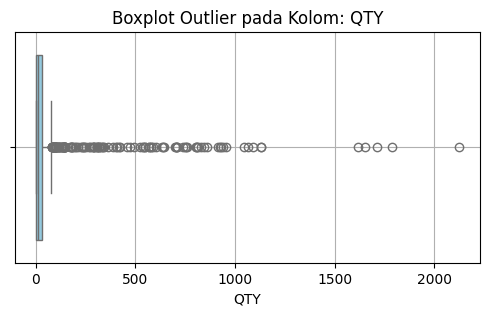

In [ ]:
# Ambil hanya kolom numerik
numeric_cols = df.select_dtypes(include='number').columns

# Loop setiap kolom numerik
for col in numeric_cols:
    plt.figure(figsize=(6, 3))
    sns.boxplot(x=df[col], color='skyblue')
    plt.title(f'Boxplot Outlier pada Kolom: {col}')
    plt.xlabel(col)
    plt.grid(True)
    plt.show()

In [ ]:
#di temukan data outlier untuk kolom QTY tetapi tidak dilakukan pergantian atau penghapusan, karena kolom tersebut berisi harga dari suatu destinasi wisata yang pada dasarnya memang berisi data berupa rentangan penjualan dari setiap mobil yang sudah di tetapkan oleh pengelola

# **missing value**

In [ ]:
miss=df.isnull().sum()
print(miss)

BRAND              0
MODEL/TYPE         0
FUEL              24
ORIGIN COUNTRY    41
QTY               70
BULAN             69
dtype: int64


/tmp/ipython-input-531955760.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=miss.values, y=miss.index, palette='coolwarm')


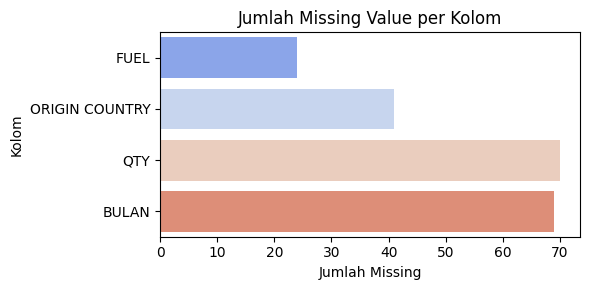

In [ ]:
# hitung jumlah missing per kolom
miss = df.isnull().sum()

# ambil hanya yang jumlahnya > 0
miss = miss[miss > 0]

plt.figure(figsize=(6, 3))
sns.barplot(x=miss.values, y=miss.index, palette='coolwarm')
plt.title('Jumlah Missing Value per Kolom')
plt.xlabel('Jumlah Missing')
plt.ylabel('Kolom')
plt.tight_layout()
plt.show()

In [ ]:
#hapus missing value, tindakan ini diambil karena data yang terdapat missing value tidak terlalu banyak (masih batas wajar)
df.dropna(inplace=True)

/tmp/ipython-input-2547672722.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.dropna(inplace=True)


In [ ]:
# --- 3. Cek lagi seluruh kolom
print("\n=== Jumlah missing value setelah semua imputasi ===")
print(df.isnull().sum())


=== Jumlah missing value setelah semua imputasi ===
BRAND             0
MODEL/TYPE        0
FUEL              0
ORIGIN COUNTRY    0
QTY               0
BULAN             0
dtype: int64


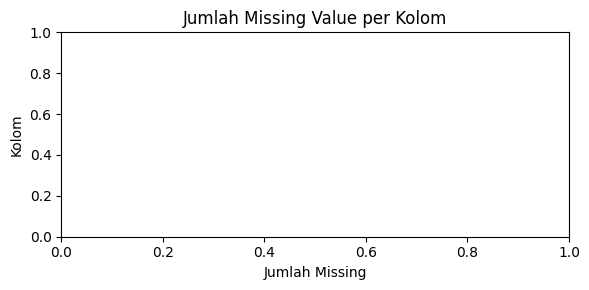

In [ ]:
# hitung jumlah missing per kolom
miss = df.isnull().sum()

# ambil hanya yang jumlahnya > 0
miss = miss[miss > 0]

plt.figure(figsize=(6, 3))
sns.barplot(x=miss.values, y=miss.index, palette='coolwarm')
plt.title('Jumlah Missing Value per Kolom')
plt.xlabel('Jumlah Missing')
plt.ylabel('Kolom')
plt.tight_layout()
plt.show()

# kolom unik

In [ ]:
df["BULAN"].unique()

<DatetimeArray>
['2025-02-28 00:00:00', '2025-03-31 00:00:00', '2025-04-30 00:00:00',
 '2025-01-31 00:00:00', '2025-06-30 00:00:00', '2025-05-31 00:00:00']
Length: 6, dtype: datetime64[ns]

In [ ]:
month_map = {
    "January": "Januari",
    "February": "Februari",
    "March": "Maret",
    "April": "April",
    "May": "Mei",
    "June": "Juni",
}

In [ ]:
# timpa kolom BULAN dengan format Indonesia
df["BULAN"] = (
    df["BULAN"]
    .dt.strftime("%B/%Y")      # contoh: "February/2025"
    .replace(month_map)        # ganti nama bulan
)

print(df)

                BRAND               MODEL/TYPE FUEL ORIGIN COUNTRY   QTY  \
0                 BMW  X3 sDrive20i G01 CKD AT    G            INA   4.0   
1                 BMW  X3 sDrive20i G01 CKD AT    G            INA   6.0   
2                 BMW  X3 sDrive20i G01 CKD AT    G            INA   3.0   
4               CHERY      Tiggo 8  Pro Luxury    G            INA  25.0   
5               CHERY      Tiggo 8  Pro Luxury    G            INA   1.0   
..                ...                      ...  ...            ...   ...   
884  MERCEDES BENZ CV        OC 500 RF 2542 DD    D          Spain   4.0   
885            SCANIA               K450CB06X2    D         Swedia   5.0   
886            SCANIA               K450CB06X2    D         Swedia   8.0   
887            SCANIA               K450CB06X2    D         Swedia   2.0   
888            SCANIA               K450CB06X2    D         Swedia   1.0   

             BULAN  
0    February/2025  
1       March/2025  
2       April/2025  
4  

/tmp/ipython-input-243432142.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["BULAN"] = (


In [ ]:
df["BULAN"].unique()

array(['February/2025', 'March/2025', 'April/2025', 'January/2025',
       'June/2025', 'May/2025'], dtype=object)

In [ ]:
df["BRAND"].unique()

array(['BMW', 'CHERY', 'FORD', 'HONDA', 'HYUNDAI - HMID', 'KIA', 'LEXUS',
       'MAZDA', 'MERCEDES-BENZ', 'MINI', 'MITSUBISHI MOTORS', 'TOYOTA',
       'WULING', 'MERCEDES-BENZ PC', 'AUDI', 'BYD', 'SUZUKI',
       'VOLVO CARS', 'BAIC', 'HYUNDAI', 'ISUZU', 'NISSAN', 'GWM',
       'SUBARU', 'MITSUBISHI FUSO', 'HINO', 'MERCEDES BENZ CV', 'SCANIA'],
      dtype=object)

In [ ]:
df.loc[df["BRAND"] == "HYUNDAI - HMID", "BRAND"] = "HYUNDAI"
df.loc[df["BRAND"] == "MERCEDES-BENZ PC", "BRAND"] = "MERCEDES-BENZ"
df.loc[df["BRAND"] == "MERCEDES BENZ CV", "BRAND"] = "MERCEDES-BENZ"

In [ ]:
df["BRAND"].unique()

array(['BMW', 'CHERY', 'FORD', 'HONDA', 'HYUNDAI', 'KIA', 'LEXUS',
       'MAZDA', 'MERCEDES-BENZ', 'MINI', 'MITSUBISHI MOTORS', 'TOYOTA',
       'WULING', 'AUDI', 'BYD', 'SUZUKI', 'VOLVO CARS', 'BAIC', 'ISUZU',
       'NISSAN', 'GWM', 'SUBARU', 'MITSUBISHI FUSO', 'HINO', 'SCANIA'],
      dtype=object)

In [ ]:
df["ORIGIN COUNTRY"].unique()

array(['INA', 'Thailand', 'South Korea', 'Korea', 'Japan', 'Malaysia',
       'Spain', 'UK', 'China', 'Germany', 'India', 'USA', 'Swedia'],
      dtype=object)

In [ ]:
df.loc[df["ORIGIN COUNTRY"] == "INA", "ORIGIN COUNTRY"] = "Indonesia"
df.loc[df["ORIGIN COUNTRY"] == "Korea", "ORIGIN COUNTRY"] = "South Korea"
df.loc[df["ORIGIN COUNTRY"] == "UK", "ORIGIN COUNTRY"] = "United Kingdom"
df.loc[df["ORIGIN COUNTRY"] == "USA", "ORIGIN COUNTRY"] = "United States"

In [ ]:
df["ORIGIN COUNTRY"].unique()

array(['Indonesia', 'Thailand', 'South Korea', 'Japan', 'Malaysia',
       'Spain', 'United Kingdom', 'China', 'Germany', 'India',
       'United States', 'Swedia'], dtype=object)

# download data

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 757 entries, 0 to 888
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   BRAND           757 non-null    object 
 1   MODEL/TYPE      757 non-null    object 
 2   FUEL            757 non-null    object 
 3   ORIGIN COUNTRY  757 non-null    object 
 4   QTY             757 non-null    float64
 5   BULAN           757 non-null    object 
dtypes: float64(1), object(5)
memory usage: 41.4+ KB


In [ ]:
df.to_excel('clean_GAIKINDO_wholesales_janjun2025.xlsx', index=False)

In [ ]:
from google.colab import files
files.download('clean_GAIKINDO_wholesales_janjun2025.xlsx')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>